# Evaluation: Figures, Tables and Key Numbers

Produces every figure, table and number used in the evaluation chapter, in the order of Chapter 6:

| Section | Output |
|---|---|
| 6.1 Overall Comparison | Figure 6.1, Table 6.1, Table A.1 |
| 6.2 Caribou | Figure 6.2 |
| 6.3 EcoLife: Keep-Alive and Hardware Switching | Figure 6.3, Figure A.1 |
| 6.4 to 6.7 Function-Level Results | Figure 6.4, Table A.2 |
| 6.8 Trade-Off Between Carbon and Service Time | Figure 6.5 |
| 6.9 Sensitivity | Figure 6.6 |
| 6.10 Comparison of Caribou and EcoLife | key numbers |
| 7.4.2 Caribou | Table 7.1, Table 7.2, Table A.3, Table A.4 |

With `SAVE = True` (first code cell), figures are saved to `results/figures` (PDF and PNG) and tables to `results/tables` (CSV and HTML in Times New Roman, the HTML can be copied into Word). Each section also prints the key numbers quoted in the text.

**System boundary:** execution and keep-alive (EcoLife's carbon model), no data transfer, no network latency.
**Reference configuration:** Baseline-DE on i3, keep-alive time 10 minutes, EcoLife warm-pool rule.
**Names:** HS = hardware switching (EcoLife switching between i3 and m5zn); EcoLife-i3 and EcoLife-m5zn = EcoLife's dynamic keep-alive on a single hardware generation.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

# ---- paths (relative to the repository root) ----
REPO = Path.cwd().resolve()
if not (REPO / "results").is_dir():           # notebook started from notebooks/
    REPO = REPO.parent
RESULTS = REPO / "results"
ECOLIFE_DIR = RESULTS / "ecolife"
ECOLIFE_BREAKDOWN = ECOLIFE_DIR / "ecolife_breakdown.csv"           # reconstruct_ecolife.py, one row per run
ECOLIFE_PER_APP = ECOLIFE_DIR / "ecolife_breakdown_per_app.csv"     # reconstruct_ecolife.py, one row per run and function
KAT_DIR = RESULTS / "baseline_caribou_5minKAT"                      # evaluate_carbon.py output, Baseline and Caribou (KAT 0 to 30)
CI_DIR = REPO / "data" / "carbon"
CI_FILES = {"DE": CI_DIR / "snapshots_2026-02-10_DE-2025-hourly.csv",
            "US": CI_DIR / "snapshots_2026-02-10_US-MIDA-PJM-2025-hourly.csv"}
CI_COL = "Carbon intensity gCO₂eq/kWh (direct)"
PLACEMENTS = RESULTS / "caribou_replay_home_us" / "placements.csv"  # Caribou's hourly plan
TX_DIR = RESULTS / "transmission_home_us"                           # transmission_carbon.py output
LAT_DIR = RESULTS / "latency"                                       # latency_inputs.py output
FIGURES = RESULTS / "figures"
TABLES = RESULTS / "tables"

# ---- evaluation settings ----
EXCLUDE = ["transmission", "levers", "compare_zones"]   # result folders to ignore
CARIBOU_HOME = "US"                    # EU and US differ by <= 0.02 %
REF_KAT, REF_POOL = 10, "ecolife"      # reference keep-alive time [min] and warm-pool rule
R = "DE"                               # region of the main text ("US" for the appendix variants)
O = "US" if R == "DE" else "DE"        # the other region
WEEK = (pd.Timestamp("2025-08-25"), pd.Timestamp("2025-09-01"))
SAVE = True                           # True: save figures and tables to results/figures and results/tables
COMP = ["exec_oc", "exec_ec", "idle_oc", "idle_ec"]

# ---- style for all figures and tables ----
FONT = "Times New Roman"
plt.rcParams.update({
    "font.family": FONT, "font.size": 11,
    "mathtext.fontset": "custom", "mathtext.rm": FONT, "mathtext.it": f"{FONT}:italic", "mathtext.bf": f"{FONT}:bold",
})
BLUE, BLUE_L = "#1f4e8c", "#6fa8dc"     # Baseline (and execution in the lever figures)
RED, RED_L = "#a61c1c", "#e06666"       # Caribou (and idle time in the lever figures)
GREEN = "#2e7d1f"                       # EcoLife
GREEN_L = "#93c47d"
FN_COLOR = {"Dynamic Region": RED, "Dynamic Keep-Alive": GREEN, "Dynamic Hardware (HS)": GREEN_L}
GRID = "#e2e1dc"
if SAVE:
    for d in (FIGURES, TABLES):
        d.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", "{:.2f}".format)
pd.set_option("display.width", 200)


def signed(v, digits=1):
    """+1.2 / −1.2 with a typographic minus, for labels in figures."""
    return f"{v:+.{digits}f}".replace("-", "\u2212")


def clean_axes(ax, grid="both"):
    """Light grid, no top/right frame."""
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.6)
        ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)


def save(fig, name):
    fig.tight_layout()
    if SAVE:
        for ext in ("pdf", "png"):
            fig.savefig(FIGURES / f"{name}.{ext}", dpi=200, bbox_inches="tight")
    plt.show()


def show_table(t, name, caption, fmt=None):
    """Display a table in Times New Roman and save it as CSV and HTML (copy the HTML into Word)."""
    if SAVE:
        t.to_csv(TABLES / f"{name}.csv", encoding="utf-8-sig")
    t = t.copy()
    t.columns.name, t.index.name = t.index.name, None   # first column name in the same header row
    fmt = fmt or {}
    formats = {c: fmt.get(c, "{:.1f}") for c in t.select_dtypes("number").columns}
    try:
        sty = (t.style.format(formats, na_rep="")
               .set_caption(caption)
               .set_table_styles([
                   {"selector": "", "props": f"font-family: '{FONT}'; border-collapse: collapse;"},
                   {"selector": "th, td", "props": f"font-family: '{FONT}'; padding: 2px 8px; text-align: right;"},
                   {"selector": "th.row_heading", "props": "text-align: left; white-space: nowrap;"},
                   {"selector": "th.index_name", "props": "text-align: left;"},
                   {"selector": "caption", "props": f"font-family: '{FONT}'; caption-side: top; text-align: left;"},
               ]))
        if SAVE:
            (TABLES / f"{name}.html").write_text(sty.to_html(), encoding="utf-8")
        display(sty)
    except ImportError:          # pandas Styler needs jinja2
        print(caption)
        display(t)

In [2]:
# ---- load all results into one frame: one row per configuration ----
HW = {"old (i3)": "i3", "new (m5zn)": "m5zn"}


def load_evaluate_carbon():
    rows = []
    for path in sorted(RESULTS.rglob("summary.csv")):
        folder = path.parent
        settings_file = folder / "settings.json"
        if any(x in str(folder) for x in EXCLUDE) or not settings_file.exists():
            continue
        settings = json.loads(settings_file.read_text(encoding="utf-8"))
        if settings.get("start_minute", 20) != 20 or "direct" not in settings.get("column", "direct"):
            continue
        s = pd.read_csv(path, encoding="utf-8-sig")
        if "pool_rule" not in s:   # older runs without the pool-rule option behave like "lambda"
            s["pool_rule"] = settings.get("pool_rule", "lambda")
        text = (str(folder) + str(settings.get("placements", ""))).lower()
        s["home"] = "EU" if "home_eu" in text else ("US" if "home_us" in text else None)
        rows.append(s)
    s = pd.concat(rows, ignore_index=True)
    out = pd.DataFrame({
        "approach": np.where(s["scenario"] == "caribou", "Caribou", "Baseline"),
        "region": s["scenario"].map({"fixed_eu-central-1": "DE", "fixed_us-east-1": "US", "caribou": "DE+US"}),
        "home": s["home"].where(s["scenario"] == "caribou"),
        "hardware": s["hardware"].map(HW),
        "kat": s["kat_min"].astype(str).str.lower().astype(float),
        "pool_rule": s["pool_rule"],
        "service_time_s": s["service_time_s"] / s["invocations"],   # mean service time per call
        "cold_share": s["cold"] / s["invocations"],
    })
    for c in COMP + ["total_g"]:
        out[c.replace("_g", "")] = s[c] / 1000                         # kg
    return out


def load_ecolife():
    head = ECOLIFE_BREAKDOWN.read_text(encoding="utf-8-sig").splitlines()[0]
    if head.count(";") > head.count(","):   # saved by German Excel
        e = pd.read_csv(ECOLIFE_BREAKDOWN, sep=";", decimal=",", thousands=".", encoding="utf-8-sig")
    else:
        e = pd.read_csv(ECOLIFE_BREAKDOWN, encoding="utf-8-sig")
    e = e[e["region"].isin(["DE", "US"]) & e["variant"].isin(["fix_i3", "fix_m5zn", "PairA"])]
    per_run = eco_app.groupby("run")[["cold", "calls"]].sum()
    cold = (per_run.cold / per_run.calls).reindex(e["region"] + "_" + e["variant"]).values
    out = pd.DataFrame({
        "approach": "EcoLife", "region": e["region"].values, "home": None,
        "hardware": e["variant"].map({"fix_i3": "i3", "fix_m5zn": "m5zn", "PairA": "HS"}).values,
        "kat": np.nan, "pool_rule": "native",
        "service_time_s": e["avg_service_time_s"].values,
        "cold_share": cold,
    })
    for c in COMP + ["total_g"]:
        out[c.replace("_g", "")] = e[c].values / 1000
    return out


def load_per_app(folder):
    """Baseline or Caribou per function, all KAT, hardware renamed; Caribou's two regions summed."""
    d = pd.read_csv(KAT_DIR / folder / "per_app.csv", encoding="utf-8-sig")
    if "pool_rule" in d:
        d = d[d.pool_rule == REF_POOL]
    d = d.assign(hardware=d.hardware.map(HW))
    cols = ["invocations", "cold", "service_time_s", "idle_min", "total_g"] + COMP
    return d.groupby(["app", "hardware", "kat_min"])[cols].sum()


eco_app = pd.read_csv(ECOLIFE_PER_APP, encoding="utf-8-sig")              # EcoLife per run and function
df = pd.concat([load_evaluate_carbon(), load_ecolife()], ignore_index=True)
df["rest"] = df["total"] - df[COMP].sum(axis=1)   # idle not attributable (only EcoLife HS, ~0.01 kg)
df = df.drop_duplicates(["approach", "region", "home", "hardware", "kat", "pool_rule"]).reset_index(drop=True)


def pick(approach, region=None, hardware=None, kat=REF_KAT, pool=REF_POOL, home=CARIBOU_HOME):
    """One configuration. Region is ignored for Caribou, KAT and pool rule for EcoLife."""
    q = df[(df["approach"] == approach) & (df["hardware"] == hardware)]
    q = q[q["home"] == home] if approach == "Caribou" else q[q["region"] == region]
    if approach != "EcoLife":
        q = q[(q["kat"] == kat) & (q["pool_rule"] == pool)]
    if len(q) != 1:
        raise ValueError(f"{len(q)} rows for {approach}/{region}/{hardware}/KAT {kat}/{pool}")
    return q.iloc[0]


def name(approach, region=None, hardware=None):
    """Names as defined in the methodology."""
    if approach == "Baseline":
        return f"Baseline-{region} ({hardware})"
    if approach == "Caribou":
        return f"Caribou ({hardware})"
    return f"EcoLife {region} (HS)" if hardware == "HS" else f"Keep-alive-{region} ({hardware})"

ref = pick("Baseline", R, "i3")
pct = lambda row: 100 * (row.total / ref.total - 1)   # change against the reference [%]
print(f"Reference: Baseline-{R} (i3), KAT {REF_KAT} = {ref.total:.2f} kg, {ref.service_time_s:.2f} s")

Reference: Baseline-DE (i3), KAT 10 = 158.02 kg, 3.41 s


## 6.1 Overall Comparison
Figure 6.1: total CO₂ of the week per configuration, operational solid, embodied hatched. Baseline and Caribou at the reference keep-alive time, EcoLife with dynamic keep-alive and HS.
Table 6.1 (main text): the eight configurations of Figure 6.1. Table A.1 (appendix): all twelve configurations with all components.

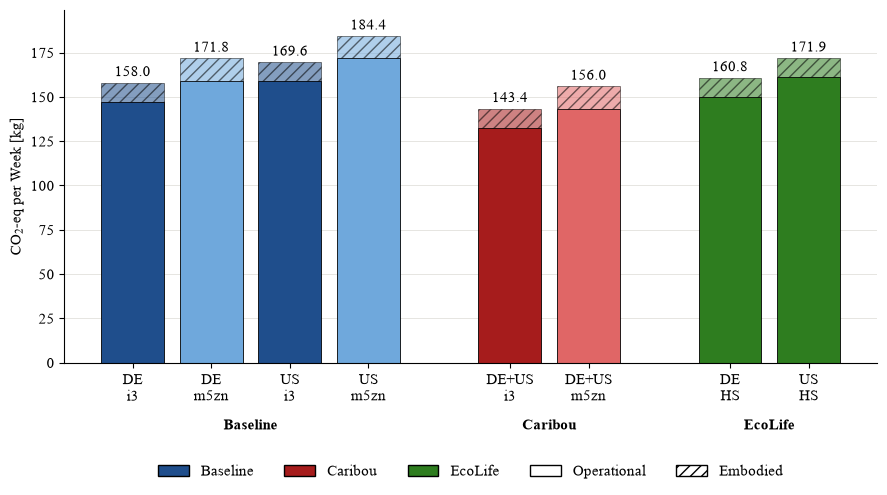

Configuration,Hardware,Total [kg],Δ [%],Service time [s]
"Baseline-DE (i3), reference",i3,158.0,+0.0,3.41
Baseline-DE (m5zn),m5zn,171.8,+8.7,2.75
Baseline-US (i3),i3,169.6,+7.3,3.41
Baseline-US (m5zn),m5zn,184.4,+16.7,2.75
Caribou (i3),i3,143.4,-9.3,3.42
Caribou (m5zn),m5zn,156.0,-1.3,2.76
Keep-alive-DE (i3),i3,150.8,-4.6,3.51
Keep-alive-DE (m5zn),m5zn,162.2,+2.6,2.84
Keep-alive-US (i3),i3,161.6,+2.3,3.53
Keep-alive-US (m5zn),m5zn,173.5,+9.8,2.86


Configuration,Region,Hardware,Keep-alive,Total [kg],Execution [kg],Idle [kg],Operational [kg],Embodied [kg],Δ [%],Service time [s],Cold starts [%]
"Baseline-DE (i3), reference",DE,i3,"fixed, 10 min",158.0,114.7,43.3,147.1,10.9,+0.0,3.41,7.2
Baseline-DE (m5zn),DE,m5zn,"fixed, 10 min",171.8,116.8,55.0,159.2,12.7,+8.7,2.75,7.2
Baseline-US (i3),US,i3,"fixed, 10 min",169.6,123.2,46.4,158.7,10.9,+7.3,3.41,7.2
Baseline-US (m5zn),US,m5zn,"fixed, 10 min",184.4,125.6,58.7,171.7,12.7,+16.7,2.75,7.2
Caribou (i3),"DE and US, hourly",i3,"fixed, 10 min",143.4,103.9,39.5,132.5,10.9,-9.3,3.42,7.4
Caribou (m5zn),"DE and US, hourly",m5zn,"fixed, 10 min",156.0,105.7,50.3,143.3,12.7,-1.3,2.76,7.4
Keep-alive-DE (i3),DE,i3,dynamic,150.8,117.5,33.2,140.9,9.9,-4.6,3.51,11.9
Keep-alive-DE (m5zn),DE,m5zn,dynamic,162.2,120.0,42.2,151.2,11.0,+2.6,2.84,11.9
Keep-alive-US (i3),US,i3,dynamic,161.6,126.6,35.0,151.8,9.8,+2.3,3.53,12.7
Keep-alive-US (m5zn),US,m5zn,dynamic,173.5,129.3,44.2,162.7,10.9,+9.8,2.86,12.7


Embodied share: 6.1 to 8.1 %
Baseline-US vs. Baseline-DE (i3): +7.3 %
Caribou (i3) vs. Baseline-DE: -9.3 %, vs. Baseline-US: -15.5 %
m5zn vs. i3: Baseline-DE +8.7 %, Caribou +8.8 %
EcoLife DE (HS) vs. Baseline-DE (i3): +1.7 %, vs. Baseline-DE (m5zn): -6.4 %
Mean carbon intensity of the week: DE 276, US 298 gCO2eq/kWh (US +8.0 %)


In [3]:
CONFIGS = [  # (approach, region, hardware); EcoLife on a single hardware generation = "Keep-alive", only in the tables
    ("Baseline", "DE", "i3"), ("Baseline", "DE", "m5zn"), ("Baseline", "US", "i3"), ("Baseline", "US", "m5zn"),
    ("Caribou", None, "i3"), ("Caribou", None, "m5zn"),
    ("EcoLife", "DE", "i3"), ("EcoLife", "DE", "m5zn"), ("EcoLife", "US", "i3"), ("EcoLife", "US", "m5zn"),
    ("EcoLife", "DE", "HS"), ("EcoLife", "US", "HS"),
]
FIG_COLOR = {("Baseline", "i3"): BLUE, ("Baseline", "m5zn"): BLUE_L,
             ("Caribou", "i3"): RED, ("Caribou", "m5zn"): RED_L, ("EcoLife", "HS"): GREEN}

# ---- Figure 6.1 ----
bars = [c for c in CONFIGS if c[0] != "EcoLife" or c[2] == "HS"]   # Keep-alive only in the tables
xs, x, prev = [], 0.0, None
for approach, *_ in bars:                       # gap between the groups
    if prev is not None and approach != prev:
        x += 0.8
    xs.append(x)
    x += 1.0
    prev = approach

fig, ax = plt.subplots(figsize=(9, 5.2))
top = max(pick(*c).total for c in bars)
for xi, (approach, region, hw) in zip(xs, bars):
    row = pick(approach, region, hw)
    op, emb = row.exec_oc + row.idle_oc, row.exec_ec + row.idle_ec
    col = FIG_COLOR[(approach, hw)]
    ax.bar(xi, op, color=col, edgecolor="black", linewidth=0.6, width=0.8)
    ax.bar(xi, emb, bottom=op, color=col, alpha=0.55, hatch="///", edgecolor="black", linewidth=0.6, width=0.8)
    ax.text(xi, row.total + top * 0.01, f"{row.total:.1f}", ha="center", va="bottom")
ax.set_xticks(xs)
ax.set_xticklabels([f"{r or 'DE+US'}\n{h}" for _, r, h in bars])
for group in dict.fromkeys(c[0] for c in bars):       # group name once, centred under its bars
    gx = [xi for xi, c in zip(xs, bars) if c[0] == group]
    ax.text(sum(gx) / len(gx), -0.16, group, transform=ax.get_xaxis_transform(), ha="center", va="top",
            fontweight="bold")
ax.set_ylabel("CO$_2$-eq per Week [kg]")
ax.set_ylim(0, top * 1.08)
clean_axes(ax, grid="y")
legend = [Patch(facecolor=BLUE, edgecolor="black", label="Baseline"),
          Patch(facecolor=RED, edgecolor="black", label="Caribou"),
          Patch(facecolor=GREEN, edgecolor="black", label="EcoLife"),
          Patch(facecolor="white", edgecolor="black", label="Operational"),
          Patch(facecolor="white", edgecolor="black", hatch="///", label="Embodied")]
ax.legend(handles=legend, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=5, frameon=False)
save(fig, f"6.1_main_result")

# ---- Table A.1 (all configurations) and Table 6.1 (short version) ----
rows = []
for approach, region, hw in CONFIGS:
    row = pick(approach, region, hw)
    label = (f"Keep-alive-{region} ({hw})" if approach == "EcoLife" and hw != "HS" else name(approach, region, hw)) \
            + (", reference" if (approach, region, hw) == ("Baseline", R, "i3") else "")    
    rows.append({
        "Configuration": label,
        "Region": "DE and US, hourly" if approach == "Caribou" else region,
        "Hardware": "i3 and m5zn (HS)" if hw == "HS" else hw,
        "Keep-alive": "dynamic" if approach == "EcoLife" else f"fixed, {REF_KAT} min",
        "Total [kg]": row.total,
        "Execution [kg]": row.exec_oc + row.exec_ec,
        "Idle [kg]": row.idle_oc + row.idle_ec,
        "Operational [kg]": row.exec_oc + row.idle_oc,
        "Embodied [kg]": row.exec_ec + row.idle_ec,
        "Δ [%]": pct(row),
        "Service time [s]": row.service_time_s,
        "Cold starts [%]": 100 * row.cold_share,
    })
tab_a1 = pd.DataFrame(rows).set_index("Configuration")
FMT = {"Δ [%]": "{:+.1f}", "Service time [s]": "{:.2f}"}
show_table(tab_a1[["Hardware", "Total [kg]", "Δ [%]", "Service time [s]"]], "table_6_1",
           f"Table 6.1: Emissions and mean service time per configuration. Δ relative to Baseline-{R} (i3). "
           "Keep-alive: EcoLife's dynamic keep-alive on a single hardware generation.", FMT)
show_table(tab_a1, "table_A_1",
           f"Table A.1: All configurations of the evaluated week. Δ relative to Baseline-{R} (i3). "
           "Execution and idle may not add up to the total for EcoLife (HS) by 0.01 kg of idle time that cannot be attributed.", FMT)

# ---- key numbers ----
emb_share = 100 * tab_a1["Embodied [kg]"] / tab_a1["Total [kg]"]
print(f"Embodied share: {emb_share.min():.1f} to {emb_share.max():.1f} %")
print(f"Baseline-{O} vs. Baseline-{R} (i3): {pct(pick('Baseline', O, 'i3')):+.1f} %")
car, car5 = pick("Caribou", hardware="i3"), pick("Caribou", hardware="m5zn")
print(f"Caribou (i3) vs. Baseline-{R}: {pct(car):+.1f} %, vs. Baseline-{O}: "
      f"{100 * (car.total / pick('Baseline', O, 'i3').total - 1):+.1f} %")
print(f"m5zn vs. i3: Baseline-{R} {100 * (pick('Baseline', R, 'm5zn').total / ref.total - 1):+.1f} %, "
      f"Caribou {100 * (car5.total / car.total - 1):+.1f} %")
eco = pick("EcoLife", R, "HS")
print(f"EcoLife {R} (HS) vs. Baseline-{R} (i3): {pct(eco):+.1f} %, vs. Baseline-{R} (m5zn): "
      f"{100 * (eco.total / pick('Baseline', R, 'm5zn').total - 1):+.1f} %")

# mean carbon intensity of the week (for the methodology)
if all(f.exists() for f in CI_FILES.values()):
    ci = {}
    for reg, f in CI_FILES.items():
        c = pd.read_csv(f, encoding="utf-8-sig")
        t = pd.to_datetime(c["Datetime (UTC)"])
        ci[reg] = c.loc[(t >= WEEK[0]) & (t < WEEK[1]), CI_COL].mean()
    print(f"Mean carbon intensity of the week: DE {ci['DE']:.0f}, US {ci['US']:.0f} gCO2eq/kWh "
          f"(US {100 * (ci['US'] / ci['DE'] - 1):+.1f} %)")
else:
    print("Carbon-intensity files not found, check CI_FILES")

## 6.2 Caribou
Figure 6.2: hourly carbon intensity of DE and US over the week, each hour shaded by the region in which Caribou runs, and below it Caribou's hourly saving compared with Baseline on i3 (reference keep-alive time and warm-pool rule).
The printed output covers when Caribou runs where, the hours with a negative saving, and the hours in which Caribou places the functions differently.

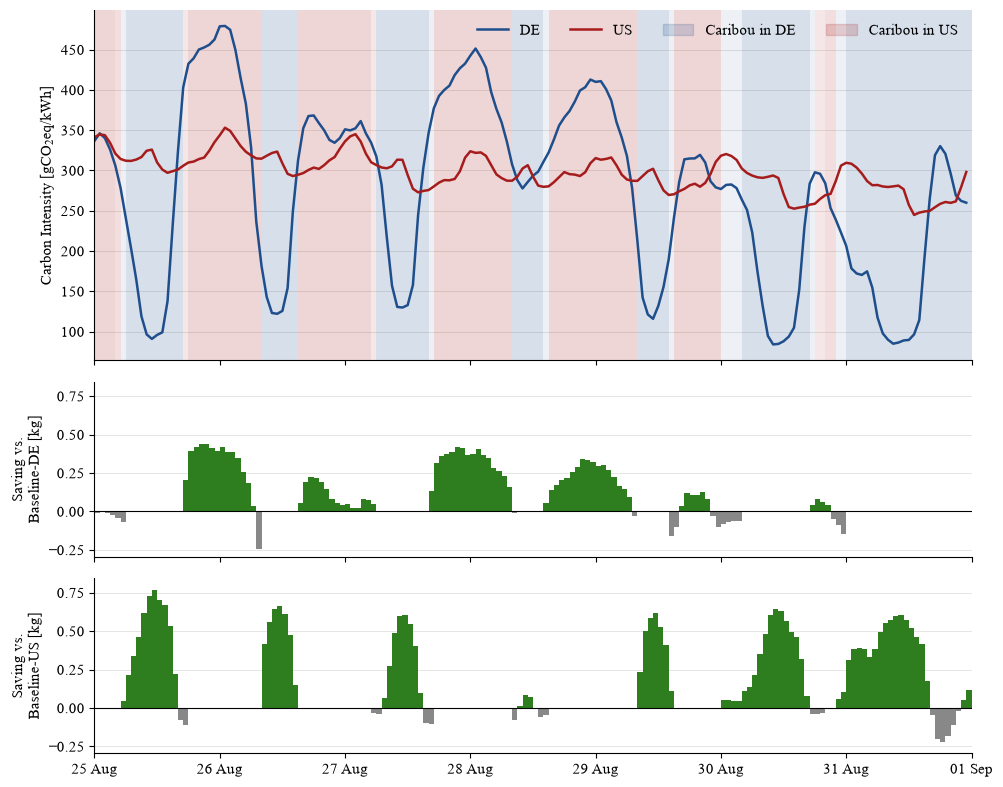

Hours with DE dirtier than US: 85 of 168; crossings of the two curves: 16
Share in DE per hour of the day (UTC), averaged over the week: {0: 0.21, 1: 0.21, 2: 0.21, 3: 0.21, 4: 0.31, 5: 0.41, 6: 0.57, 7: 0.57, 8: 1.0, 9: 1.0, 10: 1.0, 11: 1.0, 12: 1.0, 13: 1.0, 14: 0.86, 15: 0.57, 16: 0.5, 17: 0.27, 18: 0.2, 19: 0.2, 20: 0.17, 21: 0.17, 22: 0.21, 23: 0.21}
  in DE on every day: [8, 9, 10, 11, 12, 13] | on most days: [6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]


,hours in DE,in cleaner region [%]
function,,
compression,92.00,82.70
dna_visualisation,95.00,83.30
dynamic_html,77.00,82.10
graph_bfs,77.00,82.10
graph_mst,77.00,82.10
graph_pagerank,77.00,82.10
image_recognition,77.00,82.10
thumbnailer,92.00,82.70
uploader,88.00,85.10


In [4]:
import matplotlib.dates as mdates

# ---- inputs ----
placements_file = PLACEMENTS if PLACEMENTS.exists() else next(
    RESULTS.rglob(f"caribou_replay_home_{CARIBOU_HOME.lower()}/placements.csv"))   # first match if the path differs
ci = {}
for reg, f in CI_FILES.items():
    c = pd.read_csv(f, encoding="utf-8-sig")
    c["t"] = pd.to_datetime(c["Datetime (UTC)"])
    ci[reg] = c[(c.t >= WEEK[0]) & (c.t < WEEK[1])].set_index("t")[CI_COL]
ci = pd.DataFrame(ci)

p = pd.read_csv(placements_file, encoding="utf-8-sig")
p["t"] = pd.to_datetime(p.sim_date) + pd.to_timedelta(p.hour_utc, unit="h")
p["function"] = p.workflow_id.str.replace("sebs_", "").str.replace(r"-\d.*$", "", regex=True)
in_de = p.pivot_table(index="t", columns="function", values="region",
                      aggfunc=lambda s: (s == "eu-central-1").mean()).reindex(ci.index)   # 1 = in DE
share_de = in_de.mean(axis=1)                                                             # share of functions in DE


def hourly(folder):
    h = pd.read_csv(KAT_DIR / folder / "per_hour.csv", encoding="utf-8-sig")
    if "pool_rule" in h:
        h = h[h.pool_rule == REF_POOL]
    h = h[(h.kat_min == REF_KAT) & (h.hardware == "old (i3)")]
    return h.groupby(pd.to_datetime(h.datetime_utc).dt.tz_localize(None)).total_g.sum() / 1000   # kg


saving = (hourly({"DE": "baseline_eu_ecolife", "US": "baseline_us_ecolife"}[R])
          - hourly(f"caribou_home_{CARIBOU_HOME.lower()}_ecolife")).reindex(ci.index)

saving_o = (hourly({"DE": "baseline_eu_ecolife", "US": "baseline_us_ecolife"}[O])
            - hourly(f"caribou_home_{CARIBOU_HOME.lower()}_ecolife")).reindex(ci.index)

# ---- Figure 6.2 ----
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1]})
for t, s in share_de.items():                                    # background: where Caribou runs
    ax1.axvspan(t, t + pd.Timedelta(hours=1), color=BLUE if s >= 0.5 else RED,
                alpha=0.08 + 0.10 * abs(s - 0.5) * 2, lw=0)
ax1.plot(ci.index, ci.DE, color=BLUE, lw=1.8, label="DE")
ax1.plot(ci.index, ci.US, color=RED, lw=1.8, label="US")
ax1.set_ylabel("Carbon Intensity [gCO$_2$eq/kWh]")
h, l = ax1.get_legend_handles_labels()
ax1.legend(h + [Patch(color=BLUE, alpha=0.18), Patch(color=RED, alpha=0.18)],
           l + ["Caribou in DE", "Caribou in US"], loc="upper right", frameon=False, ncol=4)
lo, hi = min(saving.min(), saving_o.min()), max(saving.max(), saving_o.max())   # same scale for both saving panels
for ax, s, ref_name in [(ax2, saving, R), (ax3, saving_o, O)]:
    ax.bar(s.index, s, width=1 / 24, align="edge", color=[GREEN if v >= 0 else "#888888" for v in s])
    ax.axhline(0, color="black", lw=0.8)
    ax.set_ylim(1.2 * lo, 1.1 * hi)
    ax.set_ylabel(f"Saving vs.\nBaseline-{ref_name} [kg]")
ax3.xaxis.set_major_locator(mdates.DayLocator())
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
for ax in (ax1, ax2, ax3):
    clean_axes(ax, grid="y")
ax1.set_xlim(*WEEK)
save(fig, f"6.2_caribou")

# ---- key numbers ----
dirtier_de = ci.DE > ci.US
crossings = int((dirtier_de.astype(int).diff().abs() == 1).sum())
print(f"Hours with DE dirtier than US: {dirtier_de.sum()} of {len(ci)}; crossings of the two curves: {crossings}")
by_hour = share_de.groupby(share_de.index.hour).mean()
print("Share in DE per hour of the day (UTC), averaged over the week:", by_hour.round(2).to_dict())
print("  in DE on every day:", list(by_hour[by_hour == 1].index), "| on most days:", list(by_hour[by_hour >= 0.5].index))
cleaner_de = (~dirtier_de).astype(int)
fn_tab = pd.DataFrame({"hours in DE": in_de.sum(),
                       "in cleaner region [%]": 100 * (in_de.round() == cleaner_de.values[:, None]).mean()})
display(fn_tab.round(1))

## 6.3 EcoLife: Keep-Alive and Hardware Switching
Figure 6.3: each lever is the difference between two configurations that differ only in this lever, split into execution (blue) and idle time (red), each operational (solid) and embodied (hatched). Percent of the reference.
Figure A.1 (appendix): the two fixed levers once at fixed keep-alive time (Baseline) and once under EcoLife's dynamic keep-alive (EcoLife-i3 and EcoLife-m5zn). Single EcoLife run each, so supplement only.

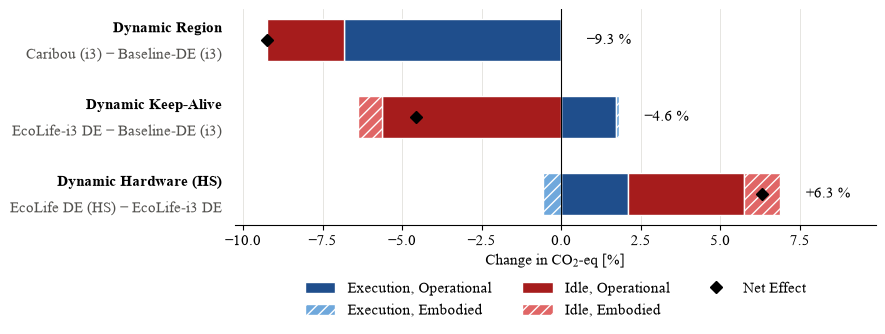

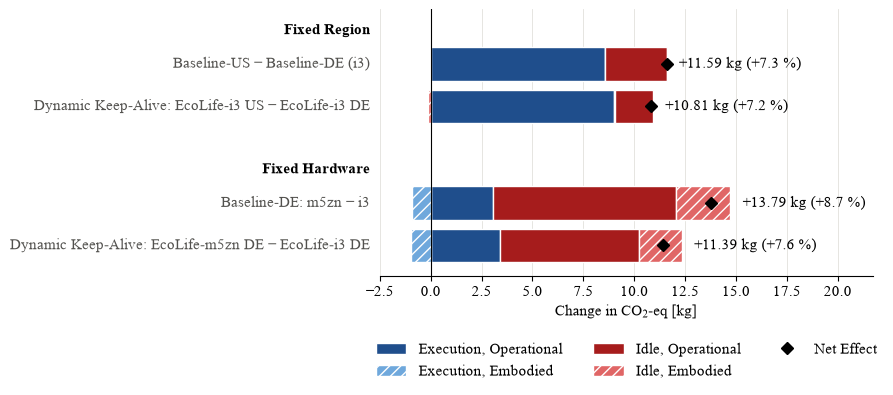

,exec_oc,exec_ec,idle_oc,idle_ec,rest,total,%
Dynamic Region,-10.79,0.01,-3.84,0.00,0.00,-14.62,-9.25
Dynamic Keep-Alive,2.70,0.17,-8.91,-1.19,0.00,-7.23,-4.58
Dynamic Hardware (HS),3.32,-0.91,5.78,1.79,0.01,9.99,6.32


Region: operational execution -9.9 %, operational idle -10.0 %, embodied +0.01 kg
Keep-alive: idle -10.10 kg, execution +2.87 kg (= 28 % of the idle saving); idle share of the reference 27.4 %
Hardware (HS): +9.99 kg, of which idle 76 %; embodied saving of execution -0.91 kg vs. additional idle +7.57 kg
Warm instance, per idle minute, m5zn vs. i3: operational +23 %, embodied +52 %, total +27 %
Fixed Region    Baseline-US − Baseline-DE (i3)                          +7.34 %
Fixed Region    Dynamic Keep-Alive: EcoLife-i3 US − EcoLife-i3 DE       +7.17 %
Fixed Hardware  Baseline-DE: m5zn − i3                                  +8.73 %
Fixed Hardware  Dynamic Keep-Alive: EcoLife-m5zn DE − EcoLife-i3 DE     +7.56 %


In [5]:
STYLE = {  # component: (colour, hatch, legend label)
    "exec_oc": (BLUE, None, "Execution, Operational"),
    "exec_ec": (BLUE_L, "///", "Execution, Embodied"),
    "idle_oc": (RED, None, "Idle, Operational"),
    "idle_ec": (RED_L, "///", "Idle, Embodied"),
}
eco_i3 = pick("EcoLife", R, "i3")
LEVERS = [  # (name, comparison, new, old)
    ("Dynamic Region", f"Caribou (i3) − Baseline-{R} (i3)", pick("Caribou", hardware="i3"), ref),
    ("Dynamic Keep-Alive", f"EcoLife-i3 {R} − Baseline-{R} (i3)", eco_i3, ref),
    ("Dynamic Hardware (HS)", f"EcoLife {R} (HS) − EcoLife-i3 {R}", pick("EcoLife", R, "HS"), eco_i3),
]
lev = pd.DataFrame({n: new[COMP + ["rest", "total"]] - old[COMP + ["rest", "total"]]
                    for n, _, new, old in LEVERS}).T.astype(float)
lev["%"] = 100 * lev["total"] / ref.total


def component_bars(ax, y, diffs, scale):
    """Stack the four components of one lever: negative to the left, positive to the right."""
    pos = neg = 0.0
    for c, (col, hatch, _) in STYLE.items():
        v = diffs[c] * scale
        ax.barh(y, abs(v), left=pos if v >= 0 else neg + v, height=0.55,
                color=col, hatch=hatch, edgecolor="white", linewidth=1.0)
        pos, neg = (pos + v, neg) if v >= 0 else (pos, neg + v)
    return pos, neg


def lever_legend(ax):
    handles = [Patch(facecolor=col, hatch=h, edgecolor="white", label=lab) for col, h, lab in STYLE.values()]
    handles.append(plt.Line2D([], [], marker="D", color="black", linestyle="None", markersize=6, label="Net Effect"))
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)


# ---- Figure 6.3 ----
fig, ax = plt.subplots(figsize=(9, 3.6))
tr = ax.get_yaxis_transform()
for y, (lever_name, cmp_, *_) in zip(range(len(LEVERS))[::-1], LEVERS):
    r = lev.loc[lever_name]
    pos, _ = component_bars(ax, y, r, 100 / ref.total)
    ax.plot(r["%"], y, marker="D", color="black", markersize=6, zorder=5)
    ax.text(max(pos, 0) + 0.8, y, f"{signed(r['%'])} %", va="center")
    ax.text(-0.02, y + 0.15, lever_name, transform=tr, ha="right", va="center", fontweight="bold")
    ax.text(-0.02, y - 0.19, cmp_, transform=tr, ha="right", va="center", color="#52514e")
share = 100 * lev[list(STYLE)] / ref.total
ax.set_xlim(min(-2, share.clip(upper=0).sum(axis=1).min() - 1), share.clip(lower=0).sum(axis=1).max() + 3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks([])
ax.set_xlabel("Change in CO$_2$-eq [%]")
clean_axes(ax, grid="x")
ax.spines["left"].set_visible(False)
lever_legend(ax)
save(fig, f"6.3_ecolife")

# ---- Figure A.1: fixed levers under fixed vs. dynamic keep-alive ----
CASES = [  # (group, label, new, old), each difference against its own reference
    ("Fixed Region", f"Baseline-{O} − Baseline-{R} (i3)", pick("Baseline", O, "i3"), ref),
    ("Fixed Region", f"Dynamic Keep-Alive: EcoLife-i3 {O} − EcoLife-i3 {R}", pick("EcoLife", O, "i3"), eco_i3),
    ("Fixed Hardware", f"Baseline-{R}: m5zn − i3", pick("Baseline", R, "m5zn"), ref),
    ("Fixed Hardware", f"Dynamic Keep-Alive: EcoLife-m5zn {R} − EcoLife-i3 {R}", pick("EcoLife", R, "m5zn"), eco_i3),
]
fig, ax = plt.subplots(figsize=(9, 4.2))
tr = ax.get_yaxis_transform()
pos_max = 0.0
for y, (group, label, new, old) in zip([3.7, 3.0, 1.4, 0.7], CASES):
    pos, _ = component_bars(ax, y, new[COMP] - old[COMP], 1.0)
    net = new.total - old.total
    ax.plot(net, y, marker="D", color="black", markersize=6, zorder=5)
    ax.text(max(pos, 0) + 0.6, y, f"{signed(net, 2)} kg ({signed(100 * net / old.total)} %)", va="center")
    ax.text(-0.02, y, label, transform=tr, ha="right", va="center", color="#52514e")
    pos_max = max(pos_max, pos)
for group, y in (("Fixed Region", 4.25), ("Fixed Hardware", 1.95)):
    ax.text(-0.02, y, group, transform=tr, ha="right", va="center", fontweight="bold")
ax.set_xlim(-2.5, pos_max + 7)
ax.xaxis.set_major_locator(plt.MultipleLocator(2.5))
ax.set_ylim(0.2, 4.6)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks([])
ax.set_xlabel("Change in CO$_2$-eq [kg]")
clean_axes(ax, grid="x")
ax.spines["left"].set_visible(False)
lever_legend(ax)
save(fig, f"6.3_ecolife")

# ---- key numbers ----
display(lev.round(2))
reg_, ka, hs = lev.iloc[0], lev.iloc[1], lev.iloc[2]
car = pick("Caribou", hardware="i3")
print(f"Region: operational execution {100 * (car.exec_oc / ref.exec_oc - 1):+.1f} %, "
      f"operational idle {100 * (car.idle_oc / ref.idle_oc - 1):+.1f} %, embodied {reg_.exec_ec + reg_.idle_ec:+.2f} kg")
idle_ka, exec_ka = ka.idle_oc + ka.idle_ec, ka.exec_oc + ka.exec_ec
print(f"Keep-alive: idle {idle_ka:+.2f} kg, execution {exec_ka:+.2f} kg "
      f"(= {100 * exec_ka / -idle_ka:.0f} % of the idle saving); idle share of the reference "
      f"{100 * (ref.idle_oc + ref.idle_ec) / ref.total:.1f} %")
print(f"Hardware (HS): {hs.total:+.2f} kg, of which idle {100 * (hs.idle_oc + hs.idle_ec) / hs.total:.0f} %; "
      f"embodied saving of execution {hs.exec_ec:+.2f} kg vs. additional idle {hs.idle_oc + hs.idle_ec:+.2f} kg")
b_app = load_per_app({"DE": "baseline_eu_ecolife", "US": "baseline_us_ecolife"}[R])
per_min = b_app.xs(REF_KAT, level="kat_min").groupby("hardware")[["idle_oc", "idle_ec", "idle_min"]].sum()
ratio = per_min[["idle_oc", "idle_ec"]].div(per_min["idle_min"], axis=0)
print(f"Warm instance, per idle minute, m5zn vs. i3: operational {100 * (ratio.loc['m5zn', 'idle_oc'] / ratio.loc['i3', 'idle_oc'] - 1):+.0f} %, "
      f"embodied {100 * (ratio.loc['m5zn', 'idle_ec'] / ratio.loc['i3', 'idle_ec'] - 1):+.0f} %, "
      f"total {100 * (ratio.sum(axis=1)['m5zn'] / ratio.sum(axis=1)['i3'] - 1):+.0f} %")
for group, label, new, old in CASES:
    print(f"{group:15s} {label:55s} {100 * (new.total / old.total - 1):+.2f} %")

## 6.4 to 6.7 Function-Level Results
Figure 6.4: the three levers of Figure 6.3 per function, relative to the same function's reference (region and keep-alive: Baseline on i3; HS: EcoLife-i3). Functions sorted by their share of total emissions, largest on top.

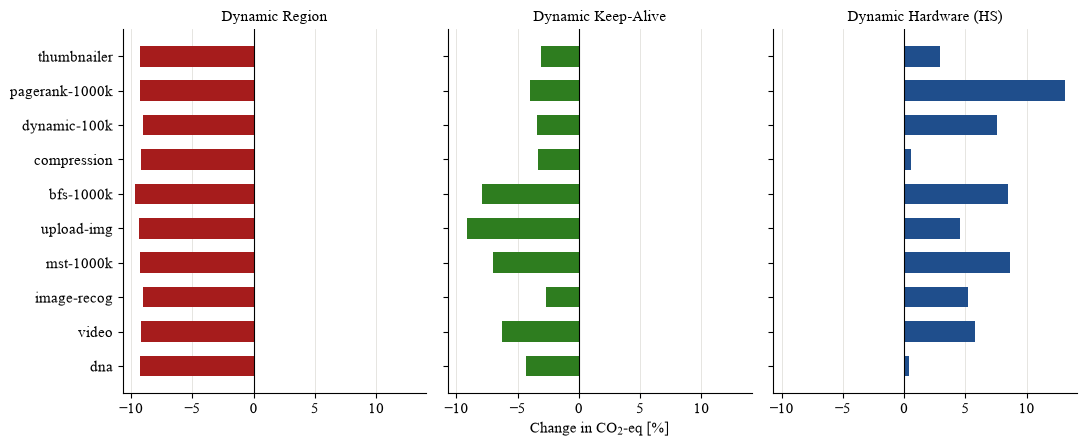

Range per lever [%]: {'Dynamic Region': (np.float64(-9.7), np.float64(-9.0)), 'Dynamic Keep-Alive': (np.float64(-9.1), np.float64(-2.7)), 'Dynamic Hardware (HS)': (np.float64(0.4), np.float64(13.1))}


In [6]:
b_app = load_per_app({"DE": "baseline_eu_ecolife", "US": "baseline_us_ecolife"}[R])
c_app = load_per_app(f"caribou_home_{CARIBOU_HOME.lower()}_ecolife")
base0, base = b_app.xs(("i3", 0), level=("hardware", "kat_min")), b_app.xs(("i3", REF_KAT), level=("hardware", "kat_min"))
base_m5 = b_app.xs(("m5zn", REF_KAT), level=("hardware", "kat_min"))
car_app = c_app.xs(("i3", REF_KAT), level=("hardware", "kat_min"))
eco_run = lambda variant: eco_app[eco_app.run == f"{R}_{variant}"].set_index("app")
e_i3, e_hs = eco_run("fix_i3"), eco_run("PairA")
order = base.total_g.sort_values().index                       # largest function on top of the figure

# ---- Figure 6.4 ----
fn = pd.DataFrame({
    "Dynamic Region": 100 * (car_app.total_g / base.total_g - 1),           # Caribou vs. Baseline
    "Dynamic Keep-Alive": 100 * (e_i3.total_g / base.total_g - 1),          # EcoLife-i3 vs. Baseline
    "Dynamic Hardware (HS)": 100 * (e_hs.total_g / e_i3.total_g - 1),       # EcoLife (HS) vs. EcoLife-i3
}).loc[order]
FN_COLOR = {"Dynamic Region": RED, "Dynamic Keep-Alive": GREEN, "Dynamic Hardware (HS)": BLUE}
fig, axs = plt.subplots(1, 3, figsize=(11, 4.6), sharey=True)
y = range(len(fn))
lo, hi = fn.min().min(), fn.max().max()
for ax, c in zip(axs, fn):
    ax.barh(list(y), fn[c], color=FN_COLOR[c], height=0.6)
    ax.set_title(c, fontsize=11)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlim(lo - 1, hi + 1)
    ax.xaxis.set_major_locator(plt.MultipleLocator(5))
    clean_axes(ax, grid="x")
axs[0].set_yticks(list(y))
axs[0].set_yticklabels(fn.index)
axs[1].set_xlabel("Change in CO$_2$-eq [%]")
save(fig, f"6.4_functions")

# ---- key numbers ----
print("Range per lever [%]:", {c: (round(fn[c].min(), 1), round(fn[c].max(), 1)) for c in fn})

### Table A.2: Properties of the Functions (Sections 6.6 and 6.7)
Table A.2 (appendix): the properties of each function that explain how EcoLife's keep-alive and hardware switching act on it, plus the key numbers quoted in the text.

In [7]:
# ---- Table A.2 ----
cs = (base0.service_time_s - base.service_time_s) / (base0.cold - base.cold)   # extra service time per cold start [s]
exe = (base0.service_time_s - cs * base0.cold) / base0.invocations              # warm execution time per call [s]
tab_a2 = pd.DataFrame({
    "Share of emissions [%]": 100 * base.total_g / base.total_g.sum(),
    "Idle share [%]": 100 * (base.idle_oc + base.idle_ec) / base.total_g,
    "Cold start / execution": cs / exe,
    "Idle minutes removed [%]": 100 * (1 - e_i3.idle_min / base.idle_min),
    "Cold starts, reference [%]": 100 * base.cold / base.invocations,
    "Cold starts, EcoLife-i3 [%]": 100 * e_i3.cold_share,
    "Δ service time [%]": 100 * (e_i3.avg_service_time_s / (base.service_time_s / base.invocations) - 1),
    "Calls on m5zn (HS) [%]": 100 * e_hs.share_calls_on_m5zn,
}).loc[order[::-1]]
tab_a2.index.name = "Function"
show_table(tab_a2, "table_A_2",
           f"Table A.2: Properties of the functions in {R}. Reference: Baseline-{R} (i3), KAT {REF_KAT}. "
           "Cold start / execution: additional service time of a cold start relative to the warm execution time, "
           "derived from the reference at KAT 0 and 10. Removed idle minutes, cold starts and service time: EcoLife-i3 "
           "against the reference.",
           {"Cold start / execution": "{:.2f}", "Δ service time [%]": "{:+.1f}"})

# ---- key numbers ----
cold_group = tab_a2.index[tab_a2["Cold start / execution"] < 0.5]
print(f"Cold start / execution < 0.5: {list(cold_group)}; idle minutes removed "
      f"{tab_a2.loc[cold_group, 'Idle minutes removed [%]'].min():.0f} to {tab_a2.loc[cold_group, 'Idle minutes removed [%]'].max():.0f} %, "
      f"others {tab_a2.drop(cold_group)['Idle minutes removed [%]'].min():.0f} to {tab_a2.drop(cold_group)['Idle minutes removed [%]'].max():.0f} %")
print("Cold starts EcoLife-i3 / reference:",
      (tab_a2["Cold starts, EcoLife-i3 [%]"] / tab_a2["Cold starts, reference [%]"]).round(1).to_dict())
pen_exec, pen_idle = (e_hs.exec_g - e_i3.exec_g) / 1000, (e_hs.idle_g - e_i3.idle_g) / 1000
print("HS penalty from execution / idle [kg]:",
      pd.DataFrame({"execution": pen_exec, "idle": pen_idle}).loc[order[::-1]].round(2).to_dict("index"))
print(f"pagerank share of the HS penalty: {100 * (pen_exec + pen_idle)['pagerank-1000k'] / (pen_exec + pen_idle).sum():.0f} %")
exec_m5 = 100 * (base_m5.exec_oc / base.exec_oc - 1)
idle_min_m5 = 100 * (((base_m5.idle_oc + base_m5.idle_ec) / base_m5.idle_min)
                     / ((base.idle_oc + base.idle_ec) / base.idle_min) - 1)
print("Fixed hardware, m5zn vs. i3 per function [%]: operational execution",
      exec_m5.loc[order[::-1]].round(1).to_dict(), "| idle per minute", idle_min_m5.round(1).agg(["min", "max"]).to_dict())

# ---- share of calls on m5zn: what does it follow? (rank correlation over the functions) ----
m5_share = tab_a2["Calls on m5zn (HS) [%]"]
candidates = {
    "cold start / execution": tab_a2["Cold start / execution"],
    "additional emissions, HS vs. EcoLife-i3": e_hs.total_g / e_i3.total_g,
    "service-time gain on m5zn (fixed hardware)": (base.service_time_s / base.invocations)
                                                  / (base_m5.service_time_s / base_m5.invocations),
}
print("Rank correlation with the share of calls on m5zn:",
      {k: float(round(m5_share.rank().corr(v.reindex(m5_share.index).rank()), 2)) for k, v in candidates.items()})

Function,Share of emissions [%],Idle share [%],Cold start / execution,Idle minutes removed [%],"Cold starts, reference [%]","Cold starts, EcoLife-i3 [%]",Δ service time [%],Calls on m5zn (HS) [%]
thumbnailer,19.9,35.0,0.71,11.3,5.6,8.0,+1.7,99.0
pagerank-1000k,18.8,10.6,0.15,55.4,8.6,28.3,+3.0,99.6
dynamic-100k,18.8,42.3,0.90,9.3,6.1,7.7,+1.3,87.7
compression,9.7,22.7,0.79,21.4,9.6,13.2,+2.6,93.9
bfs-1000k,8.6,16.3,0.19,62.4,11.7,31.4,+3.6,99.6
upload-img,8.1,41.1,1.02,27.3,9.1,14.1,+4.8,98.1
mst-1000k,6.1,14.9,0.16,58.5,10.3,28.1,+2.8,100.0
image-recog,5.6,22.8,2.42,26.7,10.2,13.2,+6.0,83.3
video,3.2,37.0,1.11,23.4,6.1,11.3,+5.4,76.6
dna,1.2,17.9,0.39,57.2,13.0,43.0,+11.2,98.5


Cold start / execution < 0.5: ['pagerank-1000k', 'bfs-1000k', 'mst-1000k', 'dna']; idle minutes removed 55 to 62 %, others 9 to 27 %
Cold starts EcoLife-i3 / reference: {'thumbnailer': 1.4, 'pagerank-1000k': 3.3, 'dynamic-100k': 1.2, 'compression': 1.4, 'bfs-1000k': 2.7, 'upload-img': 1.6, 'mst-1000k': 2.7, 'image-recog': 1.3, 'video': 1.8, 'dna': 3.3}
HS penalty from execution / idle [kg]: {'thumbnailer': {'execution': -1.69, 'idle': 2.6}, 'pagerank-1000k': {'execution': 3.46, 'idle': 0.29}, 'dynamic-100k': {'execution': -0.56, 'idle': 2.72}, 'compression': {'execution': -0.02, 'idle': 0.1}, 'bfs-1000k': {'execution': 0.85, 'idle': 0.21}, 'upload-img': {'execution': -0.48, 'idle': 1.01}, 'mst-1000k': {'execution': 0.62, 'idle': 0.15}, 'image-recog': {'execution': 0.21, 'idle': 0.24}, 'video': {'execution': 0.04, 'idle': 0.24}, 'dna': {'execution': -0.02, 'idle': 0.03}}
pagerank share of the HS penalty: 37 %
Fixed hardware, m5zn vs. i3 per function [%]: operational execution {'thumbnai

## 6.8 Trade-Off Between Carbon and Service Time
Figure 6.5: change in mean service time and emissions of six configurations relative to the reference. Lines connect the i3 and m5zn configurations of the same approach; the lower left quadrant is faster and cleaner.
The printed output gives the trade-off per lever quoted in the text (no table in the thesis).

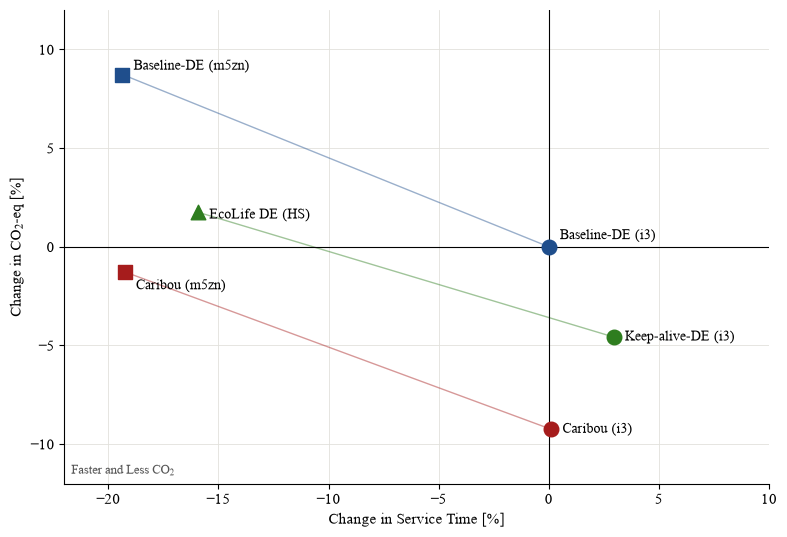

,Δ service time [%],Δ CO2 [%],Service time per % CO2
Lever,,,
Fixed Region (US Instead of DE),0.00,7.34,NaN
Dynamic Region (Caribou),0.12,-9.25,NaN
Dynamic Keep-Alive (EcoLife-i3),2.95,-4.58,0.65
Fixed Hardware (m5zn Instead of i3),-19.36,8.73,2.22
Dynamic Hardware (EcoLife HS),-18.87,6.32,2.98


In [8]:
eco_i3 = pick("EcoLife", R, "i3")
CONF = [  # (approach, region, hardware, colour, marker, label offset in points)
    ("Baseline", R, "i3", BLUE, "o", (8, 8)),
    ("Baseline", R, "m5zn", BLUE, "s", (8, 6)),
    ("Caribou", None, "i3", RED, "o", (8, 0)),
    ("Caribou", None, "m5zn", RED, "s", (8, -10)),
    ("EcoLife", R, "i3", GREEN, "o", (8, 0)),
    ("EcoLife", R, "HS", GREEN, "^", (8, -2)),
]
pt = {}
for a, reg, hw, *_ in CONF:
    row = pick(a, reg, hw)
    pt[(a, hw)] = (100 * (row.service_time_s / ref.service_time_s - 1), pct(row))

# ---- Figure 6.5 ----
fig, ax = plt.subplots(figsize=(8, 5.5))
for a, h1, h2, col in [("Baseline", "i3", "m5zn", BLUE), ("Caribou", "i3", "m5zn", RED), ("EcoLife", "i3", "HS", GREEN)]:
    (x1, y1), (x2, y2) = pt[(a, h1)], pt[(a, h2)]
    ax.plot([x1, x2], [y1, y2], color=col, lw=1, alpha=0.45, zorder=1)
for a, reg, hw, col, m, off in CONF:
    ax.scatter(*pt[(a, hw)], marker=m, s=110, color=col, zorder=3)
    ax.annotate(name(a, reg, hw), pt[(a, hw)], textcoords="offset points", xytext=off, fontsize=10, va="center")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-22, 10)
ax.set_ylim(-12, 12)
ax.text(0.01, 0.02, "Faster and Less CO$_2$", transform=ax.transAxes, fontsize=9, color="#555")
ax.set_xlabel("Change in Service Time [%]")
ax.set_ylabel("Change in CO$_2$-eq [%]")
clean_axes(ax)
save(fig, f"6.5_carbon_vs_service_time")

# ---- key numbers: trade-off per lever, relative to the reference ----
rows = []
for lever, new, old in [
    (f"Fixed Region ({O} Instead of {R})", pick("Baseline", O, "i3"), ref),
    ("Dynamic Region (Caribou)", pick("Caribou", hardware="i3"), ref),
    ("Dynamic Keep-Alive (EcoLife-i3)", eco_i3, ref),
    ("Fixed Hardware (m5zn Instead of i3)", pick("Baseline", R, "m5zn"), ref),
    ("Dynamic Hardware (EcoLife HS)", pick("EcoLife", R, "HS"), eco_i3),
]:
    dt = 100 * (new.service_time_s - old.service_time_s) / ref.service_time_s
    dc = 100 * (new.total - old.total) / ref.total
    rows.append({"Lever": lever, "Δ service time [%]": dt, "Δ CO2 [%]": dc,
                 "Service time per % CO2": abs(dt / dc) if abs(dt) >= 0.5 else np.nan})
display(pd.DataFrame(rows).set_index("Lever").round(2))

## 6.9 Sensitivity
Figure 6.6: emissions of the fixed configurations over the keep-alive time (0 to 30 min in steps of 5), relative to the reference. EcoLife does not use a fixed keep-alive time and is shown as horizontal lines.
The printed output covers the hardware break-even, EcoLife against the best fixed keep-alive time, the warm-pool rule and Caribou's home region.

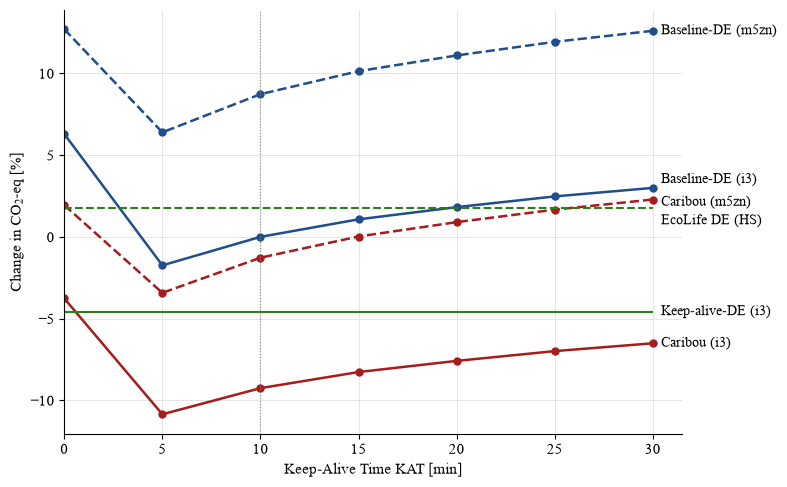

Best fixed KAT for Baseline-DE (i3): 5 min (155.27 kg); KAT 5 to 30 spans 4.7 % of the reference
EcoLife-i3 DE: -4.6 % vs. KAT 10, -2.9 % vs. the best fixed KAT
Caribou saving per KAT [%]: i3 {0.0: -9.46, 5.0: -9.27, 10.0: -9.25, 15.0: -9.24, 20.0: -9.24, 25.0: -9.23, 30.0: -9.23} | m5zn {0.0: -9.55, 5.0: -9.23, 10.0: -9.2, 15.0: -9.18, 20.0: -9.18, 25.0: -9.17, 30.0: -9.16}
m5zn vs. i3 (Baseline-DE) per KAT, totals in %, components in kg:


,total,operational,embodied,execution [kg],idle [kg]
kat,,,,,
0.00,6.03,7.05,-11.80,10.13,0.00
5.00,8.28,7.84,14.32,2.26,10.59
10.00,8.73,8.18,16.11,2.14,11.65
15.00,8.97,8.36,17.06,2.06,12.26
20.00,9.11,8.47,17.56,2.05,12.61
25.00,9.23,8.57,17.95,2.05,12.90
30.00,9.33,8.64,18.32,2.02,13.16


EcoLife (HS) vs. Baseline (i3) per KAT [%]: {0.0: -4.27, 5.0: 3.55, 10.0: 1.75, 15.0: 0.67, 20.0: -0.07, 25.0: -0.71, 30.0: -1.21}
Faster configurations, Caribou (m5zn) minus EcoLife (HS) [kg]: {0.0: 0.3, 5.0: -8.17, 10.0: -4.78, 15.0: -2.73, 20.0: -1.34, 25.0: -0.13, 30.0: 0.85}
Caribou (i3) minus EcoLife-i3 [kg]: {0.0: 1.28, 5.0: -9.92, 10.0: -7.39, 15.0: -5.84, 20.0: -4.76, 25.0: -3.81, 30.0: -3.06}
Caribou home EU vs. US [%]: {'i3': 0.015, 'm5zn': 0.015}


In [9]:
def series(approach, hw, pool=REF_POOL):
    """All KAT values of one fixed configuration, indexed by KAT."""
    q = df[(df.approach == approach) & (df.hardware == hw) & (df.pool_rule == pool) & np.isfinite(df.kat)]
    q = q[q.home == CARIBOU_HOME] if approach == "Caribou" else q[q.region == R]
    return q.set_index("kat").sort_index()


# ---- Figure 6.6 ----
fig, ax = plt.subplots(figsize=(8, 5))
for approach, hw, col, ls in [("Baseline", "i3", BLUE, "-"), ("Baseline", "m5zn", BLUE, "--"),
                              ("Caribou", "i3", RED, "-"), ("Caribou", "m5zn", RED, "--")]:
    s = series(approach, hw)
    y = 100 * (s.total / ref.total - 1)
    ax.plot(s.index, y, color=col, ls=ls, marker="o", ms=5, lw=1.8)
    off = {("Baseline", "i3"): (6, 6), ("Caribou", "m5zn"): (6, -2)}.get((approach, hw), (6, 0))
    ax.annotate(name(approach, R, hw), (s.index[-1], y.iloc[-1]), textcoords="offset points",
                xytext=off, va="center", fontsize=10)
for hw, ls in [("i3", "-"), ("HS", "--")]:
    y = pct(pick("EcoLife", R, hw))
    ax.hlines(y, 0, 30, color=GREEN, ls=ls, lw=1.5)
    ax.annotate(name("EcoLife", R, hw), (30, y), textcoords="offset points", xytext=(6, -9 if hw == "HS" else 0),
                va="center", fontsize=10)
ax.axvline(REF_KAT, color="#888", lw=0.8, ls=":")
ax.set_xlabel("Keep-Alive Time KAT [min]")
ax.set_ylabel("Change in CO$_2$-eq [%]")
ax.set_xlim(left=0)
clean_axes(ax)
save(fig, f"6.6_sensitivity_kat")

# ---- key numbers: keep-alive time ----
b, b5 = series("Baseline", "i3"), series("Baseline", "m5zn")
c, c5 = series("Caribou", "i3"), series("Caribou", "m5zn")
eco_i3, eco_hs = pick("EcoLife", R, "i3"), pick("EcoLife", R, "HS")
best = b.total.idxmin()
print(f"Best fixed KAT for Baseline-{R} (i3): {best:g} min ({b.total.min():.2f} kg); "
      f"KAT 5 to 30 spans {100 * (b.total.loc[5:].max() - b.total.loc[5:].min()) / ref.total:.1f} % of the reference")
print(f"EcoLife-i3 {R}: {pct(eco_i3):+.1f} % vs. KAT {REF_KAT}, "
      f"{100 * (eco_i3.total / b.total.min() - 1):+.1f} % vs. the best fixed KAT")
print("Caribou saving per KAT [%]: i3", (100 * (c.total / b.total - 1)).round(2).to_dict(),
      "| m5zn", (100 * (c5.total / b5.total - 1)).round(2).to_dict())
hw_tab = pd.DataFrame({"total": 100 * (b5.total / b.total - 1),
                       "operational": 100 * ((b5.exec_oc + b5.idle_oc) / (b.exec_oc + b.idle_oc) - 1),
                       "embodied": 100 * ((b5.exec_ec + b5.idle_ec) / (b.exec_ec + b.idle_ec) - 1),
                       "execution [kg]": (b5.exec_oc + b5.exec_ec) - (b.exec_oc + b.exec_ec),
                       "idle [kg]": (b5.idle_oc + b5.idle_ec) - (b.idle_oc + b.idle_ec)})
print(f"m5zn vs. i3 (Baseline-{R}) per KAT, totals in %, components in kg:")
display(hw_tab.round(2))
print("EcoLife (HS) vs. Baseline (i3) per KAT [%]:", (100 * (eco_hs.total / b.total - 1)).round(2).to_dict())
print("Faster configurations, Caribou (m5zn) minus EcoLife (HS) [kg]:", (c5.total - eco_hs.total).round(2).to_dict())
print("Caribou (i3) minus EcoLife-i3 [kg]:", (c.total - eco_i3.total).round(2).to_dict())

# ---- key numbers: home region ----
homes = df[(df.approach == "Caribou") & (df.kat == REF_KAT) & (df.pool_rule == REF_POOL)].pivot_table(
    index="hardware", columns="home", values="total")
print("Caribou home EU vs. US [%]:", (100 * (homes["EU"] / homes["US"] - 1)).round(3).to_dict())

## 6.10 Comparison of Caribou and EcoLife
Key numbers for the comparison of the two techniques, in both regions.

In [10]:
car = pick("Caribou", hardware="i3")
for reg in ["DE", "US"]:
    base_r, eco_r, eco_i3_r = pick("Baseline", reg, "i3"), pick("EcoLife", reg, "HS"), pick("EcoLife", reg, "i3")
    region_saving = 100 * (1 - car.total / base_r.total)
    keepalive_saving = 100 * (1 - eco_i3_r.total / base_r.total)
    print(f"{reg}: Caribou (i3) vs. EcoLife {reg} (HS) {100 * (car.total / eco_r.total - 1):+.1f} %, "
          f"vs. EcoLife-i3 {reg} {100 * (car.total / eco_i3_r.total - 1):+.1f} %; "
          f"region saves {region_saving:.1f} %, keep-alive {keepalive_saving:.1f} % "
          f"(ratio {region_saving / keepalive_saving:.1f})")
print(f"Caribou (m5zn) vs. EcoLife-m5zn {R}: "
      f"{100 * (pick('Caribou', hardware='m5zn').total / pick('EcoLife', R, 'm5zn').total - 1):+.1f} %")
print(f"EcoLife {R}: HS costs {pick('EcoLife', R, 'HS').total - pick('EcoLife', R, 'i3').total:.2f} kg, "
      f"the weaker lever {pick('EcoLife', R, 'i3').total - car.total:.2f} kg (EcoLife-i3 minus Caribou on i3)")

DE: Caribou (i3) vs. EcoLife DE (HS) -10.8 %, vs. EcoLife-i3 DE -4.9 %; region saves 9.3 %, keep-alive 4.6 % (ratio 2.0)
US: Caribou (i3) vs. EcoLife US (HS) -16.6 %, vs. EcoLife-i3 US -11.3 %; region saves 15.5 %, keep-alive 4.7 % (ratio 3.3)
Caribou (m5zn) vs. EcoLife-m5zn DE: -3.8 %
EcoLife DE: HS costs 9.99 kg, the weaker lever 7.39 kg (EcoLife-i3 minus Caribou on i3)


## 7.4.2 Caribou
Tables for the data-transfer and latency discussion in Section 7.4.2 (input: `transmission_carbon.py`, `latency_inputs.py`).

In [11]:
# ---- inputs: output of transmission_carbon.py and latency_inputs.py ----
APP_NAME = {"sebs_compression": "compression", "sebs_dna_visualisation": "dna", "sebs_dynamic_html": "dynamic",
            "sebs_graph_bfs": "bfs", "sebs_graph_mst": "mst", "sebs_graph_pagerank": "pagerank",
            "sebs_image_recognition": "image-recog", "sebs_thumbnailer": "thumbnailer",
            "sebs_uploader": "upload-img", "sebs_video_processing": "video"}
tx = pd.read_csv(TX_DIR / "transmission_per_app.csv", encoding="utf-8-sig")
tx_sum = pd.read_csv(TX_DIR / "transmission_summary.csv", encoding="utf-8-sig")
net = pd.read_csv(LAT_DIR / "network_latency.csv", encoding="utf-8-sig")
dur = pd.read_csv(LAT_DIR / "durations.csv", encoding="utf-8-sig")

# ---- Table 7.1: transmission carbon per function ----
tab_tx = pd.DataFrame({
    "Function": tx.workflow.map(APP_NAME),
    "Data per invocation [MB]": tx.mb_per_call,
    "Shifted [%]": 100 * tx.shifted_share,
    "Caribou best [kg]": tx.caribou_best_g / 1000,
    "Caribou worst [kg]": tx.caribou_worst_g / 1000,
    "Baseline best [kg]": tx.baseline_best_g / 1000,
}).sort_values("Data per invocation [MB]", ascending=False).set_index("Function")
show_table(tab_tx, "table_A_transmission",
           "Table 7.1: Transmission carbon per function (home region us-east-1, best case 0.001 kWh/GB for every transfer, "
           "worst case 0.005 kWh/GB for transfers between regions only).",
           {"Data per invocation [MB]": "{:.3f}", "Caribou best [kg]": "{:.3f}", "Caribou worst [kg]": "{:.3f}",
            "Baseline best [kg]": "{:.3f}"})

# ---- Table A.3: Caribou's saving against Baseline-US (i3) ----
s = tx_sum[tx_sum.hardware == "old (i3)"].iloc[0]
tab_sav = pd.DataFrame({
    "Baseline-US [kg]": [s[f"baseline_{c}_kg"] for c in ("none", "best", "worst")],
    "Caribou [kg]": [s[f"caribou_{c}_kg"] for c in ("none", "best", "worst")],
    "Saving [%]": [100 * s[f"saving_{c}"] for c in ("none", "best", "worst")],
}, index=pd.Index(["none", "best case", "worst case"], name="Data transfer"))
show_table(tab_sav, "table_A_transmission_saving",
           "Table A.3: Caribou's saving against Baseline-US on i3 with and without data transfer "
           f"(keep-alive time {REF_KAT} minutes).", {"Baseline-US [kg]": "{:.2f}", "Caribou [kg]": "{:.2f}", "Saving [%]": "{:.1f}"})

# ---- Table 7.2: network latency ----
tab_net = net.assign(**{"From": net["from"].str.replace("aws:", ""), "To": net["to"].str.replace("aws:", "")}) \
    .set_index(["From", "To"])[["mean_ms", "median_ms", "p95_ms"]] \
    .rename(columns={"mean_ms": "Mean [ms]", "median_ms": "Median [ms]", "p95_ms": "p95 [ms]"})
show_table(tab_net, "table_A_network_latency",
           "Table 7.2: Network latency between and within the regions (CloudPing, as used by Caribou for planning).",
           {c: "{:.2f}" for c in tab_net.columns})

# ---- Table A.4: measured duration per execution on Lambda ----
tab_dur = pd.DataFrame({
    "Function": dur.workflow.map(APP_NAME),
    "US median [s]": dur.median_us_s,
    "EU median [s]": dur.median_eu_s,
    "Additional time in EU [s]": dur.penalty_corr_s,
}).sort_values("Additional time in EU [s]", ascending=False).set_index("Function")
show_table(tab_dur, "table_A_durations",
           f"Table A.4: Measured duration per execution on AWS Lambda (median, {dur.n_eu.min()} to {dur.n_us.max()} runs "
           "per function and region), input data stored in us-east-1. Additional time: EU minus US, corrected by a regional "
           "factor derived from the graph functions, which load hardly any data.",
           {c: "{:+.3f}" if c.startswith("Additional") else "{:.3f}" for c in tab_dur.columns})

# ---- key numbers quoted in the discussion ----
worst = tx.caribou_worst_g
top3 = tx.loc[tx.mb_per_call.nlargest(3).index]
print(f"Saving vs. Baseline-US (i3): none {100 * s.saving_none:.1f} %, best {100 * s.saving_best:.1f} %, "
      f"worst {100 * s.saving_worst:.1f} %")
print(f"Share of worst-case transmission carbon from the 3 functions with the most data "
      f"({', '.join(top3.workflow.map(APP_NAME))}): {100 * top3.caribou_worst_g.sum() / worst.sum():.0f} %")
print(f"Largest additional time in EU: {tab_dur['Additional time in EU [s]'].max():.1f} s")

Function,Data per invocation [MB],Shifted [%],Caribou best [kg],Caribou worst [kg],Baseline best [kg]
dna,167.259,54.5,0.702,1.711,0.769
compression,19.012,55.0,2.604,6.420,2.842
video,15.365,56.8,0.741,1.898,0.808
thumbnailer,0.794,54.4,0.371,0.904,0.404
upload-img,0.542,53.5,0.086,0.205,0.094
image-recog,0.080,46.3,0.004,0.009,0.005
pagerank,0.024,46.1,0.002,0.005,0.003
bfs,0.021,43.4,0.001,0.002,0.001
mst,0.020,46.2,0.001,0.002,0.001
dynamic,0.013,46.4,0.007,0.014,0.007


Data transfer,Baseline-US [kg],Caribou [kg],Saving [%]
none,169.62,143.40,15.5
best case,174.55,147.92,15.3
worst case,169.62,154.57,8.9


Function,US median [s],EU median [s],Additional time in EU [s]
compression,2.539,11.102,+8.705
dna,8.114,9.508,+1.848
video,1.389,2.336,+1.025
upload-img,0.085,0.643,+0.563
pagerank,12.377,12.045,+0.362
thumbnailer,0.099,0.447,+0.354
image-recog,0.335,0.495,+0.179
mst,7.118,6.827,+0.108
dynamic,0.116,0.146,+0.036
bfs,7.556,6.797,-0.335


Saving vs. Baseline-US (i3): none 15.5 %, best 15.3 %, worst 8.9 %
Share of worst-case transmission carbon from the 3 functions with the most data (dna, compression, video): 90 %
Largest additional time in EU: 8.7 s
